# 1 Load dataset

In [28]:
import numpy as np
import pandas as pd

In [ ]:
pd.set_option("display.max_columns", None)

file_id = "1jVzIRp6zxrGVDXRtuG-8mc6CzHrbQFED"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(
    url,
    parse_dates=["started_at"],
    dtype={"y_overdue": "boolean", "prev_late": "boolean"},
)

df.head()

,id,started_at,customer_id,client_id,tenant,hour,dow,month,is_weekend,plan_hours,n_batteries,model,deposit_kind,deposit_amount,price_total,prepaid_share,client_residency,block_missing,issued_by_employee_id,first_visit,client_prev_rentals,client_prev_late_rate,client_prev_lost,prev_late,days_since_prev,y_overdue,y_lost
0,65f0da3c-7abb-4f9c-b2b7-1968b8a663e2,2025-01-18 12:19:51+00:00,2975e970-5ed2-46f0-b809-f455e9873912,01d32244-c1b4-4a1a-97c1-b414ab17aa69,synth-a,15,5,1,True,72.000000,1,Trail 350,document,NaN,5720.0,0.0,local,False,23b8c1e9-3924-46de-beb1-3b9046685257,True,0,NaN,0,<NA>,NaN,False,False
1,9dddd117-7806-49e8-9857-f0891492517a,2025-01-18 13:01:54+00:00,e5ceac23-aff7-488d-aada-d07f2d6b89e7,662e7ea7-9c74-4faf-8fed-aa3b52e3b310,synth-a,16,5,1,True,2.000000,2,Cargo 500,cash,2000.0,870.0,0.0,local,False,17fc695a-07a0-4a6e-8822-e8f36c031199,False,2,NaN,0,<NA>,7.291227,False,False
2,5f2c2c26-7b12-4db4-a509-1af3c7a9b788,2025-01-18 14:32:11+00:00,3bd8a8e5-feaf-47c1-9ff9-6ac8294b1d6f,53028b18-d032-4689-8dd3-b231402c1e98,synth-a,17,5,1,True,2.000000,1,Cargo 500,document,NaN,NaN,NaN,local,False,8fadc1a6-06cb-4fb3-9a1d-e644815ef6d1,False,1,NaN,0,<NA>,19.314884,False,False
3,e9a9ea82-7552-46e3-abd2-277e49bae976,2025-01-18 14:58:59+00:00,ef4e31fe-b93b-4061-95bd-125ecfdc8f7b,918eade9-dbd4-44b9-89d6-158602d45aad,synth-c,16,5,1,True,4.016944,2,Cargo 500,NaN,NaN,NaN,NaN,NaN,True,6e996e3e-e3b1-47fc-8a34-50fc9918ee46,True,0,NaN,0,<NA>,NaN,False,False
4,2a036585-d898-484e-834d-216eb0b615c0,2025-01-18 15:12:19+00:00,d3497354-5320-4fc3-9f36-8a17065f8f69,7626e160-db24-44cb-85aa-e5ca667d6f8e,synth-b,20,5,1,True,0.794722,1,Urban 250,NaN,NaN,NaN,NaN,NaN,True,50f0fd0a-750c-4b75-8ccc-9bc2a53f8a28,True,0,NaN,0,<NA>,NaN,True,False


# 2 EDA

## 2.1 Base

In [3]:
df.shape, df.duplicated().sum()

((39344, 27), np.int64(0))

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39344 entries, 0 to 39343
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   id                     39344 non-null  str                
 1   started_at             39344 non-null  datetime64[us, UTC]
 2   customer_id            39344 non-null  str                
 3   client_id              39344 non-null  str                
 4   tenant                 39344 non-null  str                
 5   hour                   39344 non-null  int64              
 6   dow                    39344 non-null  int64              
 7   month                  39344 non-null  int64              
 8   is_weekend             39344 non-null  bool               
 9   plan_hours             39344 non-null  float64            
 10  n_batteries            39344 non-null  int64              
 11  model                  39344 non-null  str                
 12  d

In [5]:
KEYS = ["id", "started_at", "customer_id", "client_id"]
TARGET = "y_overdue"
NUM = ["hour", "month", "plan_hours", "n_batteries", "deposit_amount", "price_total",
       "prepaid_share", "client_prev_rentals", "client_prev_late_rate", "client_prev_lost",
       "days_since_prev"]
CAT = ["tenant", "dow", "model", "deposit_kind", "client_residency", "issued_by_employee_id"]
BOOL = ["is_weekend", "block_missing", "first_visit", "prev_late"]

## 2.2 Nulls

In [6]:
nulls = df.isnull().sum().sort_values(ascending=False)
nulls[nulls > 0]

deposit_amount           32508
prepaid_share            19986
client_residency         17856
price_total              17854
deposit_kind             17787
client_prev_late_rate    15960
prev_late                15960
days_since_prev          15633
y_overdue                  391
dtype: int64

In [7]:
df = df.drop(columns="y_lost").dropna(subset=["y_overdue"]).reset_index(drop=True)
df["y_overdue"] = df["y_overdue"].astype("int8")
df[BOOL] = df[BOOL].astype("float32")

In [8]:
print(df.shape, df["y_overdue"].isna().sum(), df["y_overdue"].dtype)

(38953, 26) 0 int8


# 3 Describe Data

## 3.1 NUM

In [9]:
desc = df[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["missing_%"] = (df[NUM].isna().mean() * 100).round(1)
desc["skew"] = df[NUM].skew().round(2)
desc["kurt"] = df[NUM].kurt().round(2)

q1, q3 = df[NUM].quantile(.25), df[NUM].quantile(.75)
iqr = q3 - q1
outliers = ((df[NUM] < q1 - 1.5 * iqr) | (df[NUM] > q3 + 1.5 * iqr)).mean() * 100
desc["outliers_%"] = outliers.round(1)

desc

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing_%,skew,kurt,outliers_%
hour,38953.0,12.290504,3.331980,9.000000,9.000000,9.000000,12.000000,15.000000,20.000000,20.000000,0.0,0.68,-0.69,0.0
month,38953.0,6.571715,2.813073,1.000000,1.000000,5.000000,7.000000,9.000000,12.000000,12.000000,0.0,-0.12,-0.67,0.0
plan_hours,38953.0,21.441388,38.225681,0.002778,0.542644,2.000000,4.000000,24.000000,168.000000,168.000000,0.0,2.85,7.92,9.5
n_batteries,38953.0,1.303212,0.459652,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,0.0,0.86,-1.27,0.0
deposit_amount,6806.0,2726.417867,1461.561879,1000.000000,1000.000000,2000.000000,2000.000000,3000.000000,5000.000000,5000.000000,82.5,0.47,-1.09,4.2
price_total,21277.0,2237.156084,2766.368969,270.000000,290.000000,890.000000,1440.000000,2210.000000,15362.400000,17320.000000,45.4,3.28,11.40,6.2
prepaid_share,19160.0,0.550861,0.445218,0.000000,0.000000,0.000000,0.500000,1.000000,1.000000,1.000000,50.8,-0.20,-1.71,0.0
client_prev_rentals,38953.0,2.115344,2.875652,0.000000,0.000000,0.000000,1.000000,3.000000,13.000000,26.000000,0.0,2.10,5.83,6.0
client_prev_late_rate,23225.0,0.082735,0.208251,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,40.4,3.14,9.95,12.6
client_prev_lost,38953.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,NaN,NaN,0.0


## 3.2 CAT

In [10]:
summary = pd.DataFrame({
    "nunique": df[CAT].nunique(),
    "missing": df[CAT].isna().sum(),
    "top": df[CAT].mode().iloc[0],
    "top_share_%": df[CAT].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100).round(1),
    "values": [df[c].dropna().unique().tolist() for c in CAT],
}).sort_values("nunique")
summary

,nunique,missing,top,top_share_%,values
client_residency,2,17681,local,80.4,"[local, tourist]"
tenant,3,0,synth-b,50.1,"[synth-a, synth-c, synth-b]"
deposit_kind,3,17612,none,36.7,"[document, cash, none]"
model,3,0,Cargo 500,36.1,"[Trail 350, Cargo 500, Urban 250]"
dow,7,0,5,16.2,"[5, 6, 0, 1, 2, 3, 4]"
issued_by_employee_id,12,0,344a54b8-42c1-4a62-af48-e8d550fd9d3f,12.7,"[23b8c1e9-3924-46de-beb1-3b9046685257, 17fc695..."


## 3.3 BOOL

In [11]:
bool_summary = df[BOOL].describe().T.join(
    pd.DataFrame({
        "missing_%": (df[BOOL].isna().mean() * 100).round(1),
        "share_1_%": (df[BOOL].mean() * 100).round(1),
    })
)
bool_summary

,count,mean,std,min,25%,50%,75%,max,missing_%,share_1_%
is_weekend,38953.0,0.322774,0.467543,0.0,0.0,0.0,1.0,1.0,0.0,32.299999
block_missing,38953.0,0.391703,0.488137,0.0,0.0,0.0,1.0,1.0,0.0,39.200001
first_visit,38953.0,0.395400,0.488943,0.0,0.0,0.0,1.0,1.0,0.0,39.500000
prev_late,23225.0,0.075694,0.264514,0.0,0.0,0.0,0.0,1.0,40.4,7.600000


# 4 Visualize

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

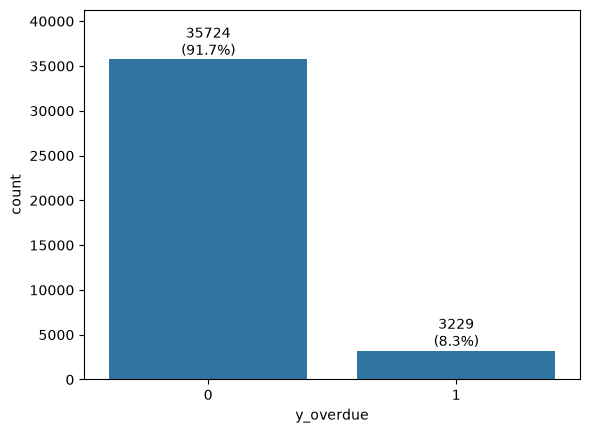

In [13]:
ax = sns.countplot(data=df, x=TARGET)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}\n({h / len(df):.1%})",
                (p.get_x() + p.get_width() / 2, h),
                ha="center", va="bottom")
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
plt.show()

## Сonclusion
Class imbalance.
The main metric is PR AUC (average precision).
Stratification is required.

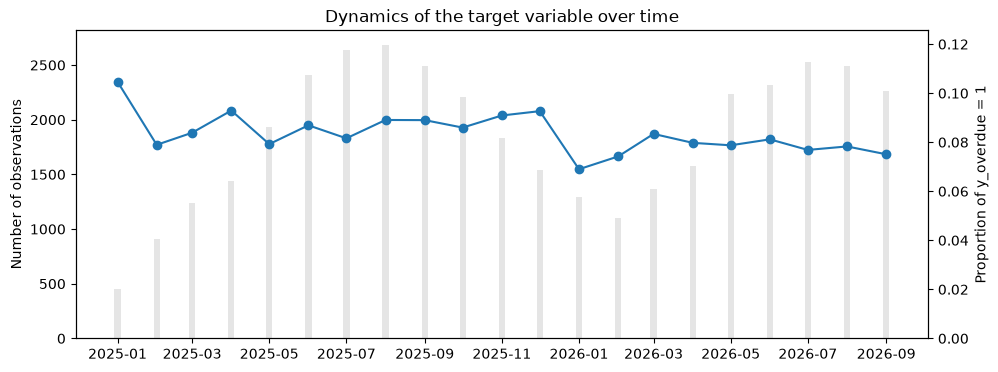

In [14]:
ts = (
    df.set_index("started_at")["y_overdue"]
      .resample("MS")
      .agg(rate="mean", n="size")
)

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(ts.index, ts["n"], width=5, alpha=0.2, color="gray")
ax1.set_ylabel("Number of observations")

ax2 = ax1.twinx()
ax2.plot(ts.index, ts["rate"], marker="o", color="C0")
ax2.set_ylabel("Proportion of y_overdue = 1")
ax2.set_ylim(0, ts["rate"].max() * 1.2)

plt.title("Dynamics of the target variable over time")
plt.show()

# 5 Correlation with target

In [20]:
from sklearn.metrics import roc_auc_score

base = df[TARGET].mean()   # The total percentage of delays, the starting point for all comparisons
base.round(3)

np.float64(0.083)

In [21]:
# Automatic sorting of features by type
const = [c for c in NUM + BOOL if df[c].nunique() <= 1]               # constants (client_prev_lost)
DISC  = [c for c in NUM if c not in const and df[c].nunique() <= 12]  # discrete: hour, month, n_batteries ...
CONT  = [c for c in NUM if c not in const and c not in DISC]          # continuous
LOW   = [c for c in CAT if df[c].nunique() <= 20]                     # categorical with few values
HIGH  = [c for c in CAT if c not in LOW]                              # with many values (issued_by_employee_id)
print("const:", const, "\nDISC:", DISC, "\nCONT:", CONT, "\nLOW:", LOW, "\nHIGH:", HIGH)

const: ['client_prev_lost'] 
DISC: ['hour', 'month', 'n_batteries', 'deposit_amount', 'prepaid_share'] 
CONT: ['plan_hours', 'price_total', 'client_prev_rentals', 'client_prev_late_rate', 'days_since_prev'] 
LOW: ['tenant', 'dow', 'model', 'deposit_kind', 'client_residency', 'issued_by_employee_id'] 
HIGH: []


## 5.1 NUM + BOOL (AUC of one feature)

In [38]:
rows = []
for c in CONT + DISC + BOOL:
    s = df[[c, TARGET]].dropna()
    rows.append({"feature": c, "n": len(s), "auc": roc_auc_score(s[TARGET], s[c])})

rank = (pd.DataFrame(rows)
          .assign(corr=lambda t: (t["auc"] - 0.55)) # 0.55–0.65: weak signal
          .sort_values("corr", ascending=False)
          .round(3))
rank

,feature,n,auc,corr
0,plan_hours,38953,0.681,0.131
1,price_total,21277,0.671,0.121
12,first_visit,38953,0.557,0.007
3,client_prev_late_rate,23225,0.549,-0.001
5,hour,38953,0.541,-0.009
10,is_weekend,38953,0.534,-0.016
13,prev_late,23225,0.518,-0.032
6,month,38953,0.508,-0.042
11,block_missing,38953,0.504,-0.046
7,n_batteries,38953,0.501,-0.049


## 5.2 Groups

In [24]:
def rate_table(c, min_n=100):
    g = df.groupby(c, dropna=False)[TARGET].agg(rate="mean", n="size")
    g = g[g["n"] >= min_n]                                   # rare groups are noisy
    g["lift"] = (g["rate"] / base).round(2)
    g["z"] = ((g["rate"] - base) / (g["rate"].clip(1e-9, 1 - 1e-9) * (1 - g["rate"].clip(1e-9, 1 - 1e-9)) / g["n"]) ** 0.5).round(1)
    g["rate_%"] = (g["rate"] * 100).round(1)
    return g[["rate_%", "n", "lift", "z"]]

for c in LOW + DISC + BOOL:
    print(f"\n=== {c} === (base {base:.1%})")
    print(rate_table(c).sort_values("rate_%").to_string())


=== tenant === (base 8.3%)
         rate_%      n  lift    z
tenant                           
synth-c     7.4   7565  0.89 -3.0
synth-a     8.0  11867  0.97 -1.1
synth-b     8.8  19521  1.06  2.6

=== dow === (base 8.3%)
     rate_%     n  lift    z
dow                         
0       7.1  5285  0.86 -3.3
3       7.1  5281  0.85 -3.5
2       7.5  5234  0.90 -2.3
1       7.9  5315  0.95 -1.1
4       8.2  5265  0.99 -0.3
5       9.7  6327  1.17  3.8
6      10.0  6246  1.21  4.6

=== model === (base 8.3%)
           rate_%      n  lift    z
model                              
Cargo 500     8.0  14050  0.97 -1.2
Trail 350     8.3  12894  1.00 -0.1
Urban 250     8.6  12009  1.04  1.4

=== deposit_kind === (base 8.3%)
              rate_%      n  lift     z
deposit_kind                           
document         4.5   5975  0.55 -13.9
cash             6.9   7526  0.83  -4.9
NaN              8.3  17612  1.00   0.1
none            12.5   7840  1.51  11.3

=== client_residency === (base 8.3

## 5.3 Dependency for continuous features

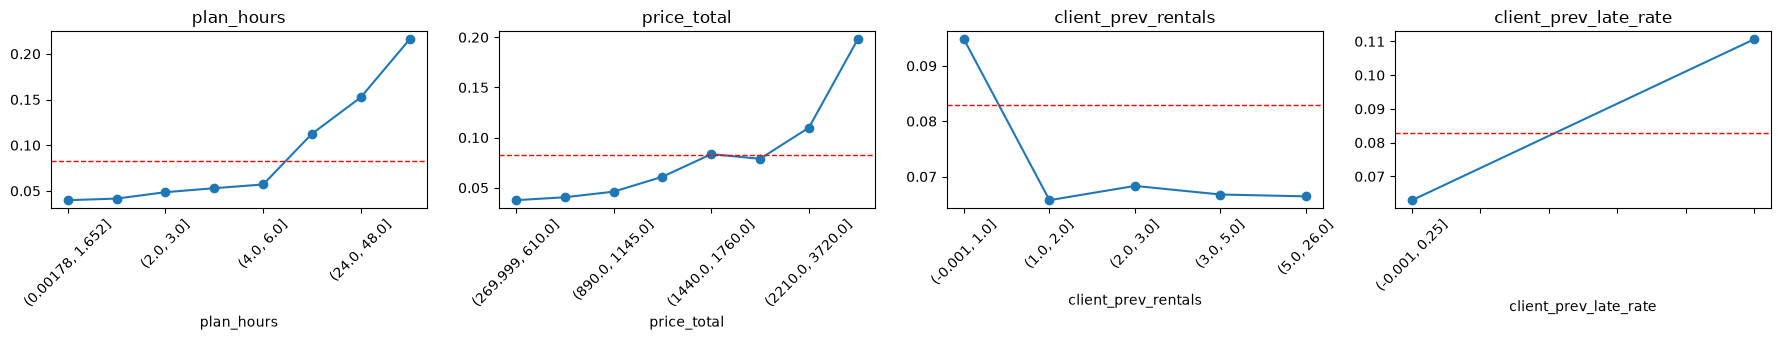

In [29]:
top = rank[rank["feature"].isin(CONT)]["feature"].head(4).tolist()
fig, axes = plt.subplots(1, len(top), figsize=(4.5 * len(top), 3.5))
for ax, c in zip(np.atleast_1d(axes), top):
    bins = pd.qcut(df[c], q=8, duplicates="drop")
    df.groupby(bins, observed=True)[TARGET].mean().plot(marker="o", ax=ax)
    ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5.4 NAs 

In [30]:
na_cols = [c for c in df.columns if df[c].isna().any() and c != TARGET]
na_effect = pd.DataFrame({
    c: {"rate_if_NA_%": df.loc[df[c].isna(), TARGET].mean() * 100,
        "rate_if_present_%": df.loc[df[c].notna(), TARGET].mean() * 100,
        "n_NA": df[c].isna().sum()}
    for c in na_cols
}).T.round(1)
na_effect

,rate_if_NA_%,rate_if_present_%,n_NA
deposit_kind,8.3,8.3,17612.0
deposit_amount,8.6,6.9,32147.0
price_total,8.4,8.2,17676.0
prepaid_share,8.2,8.3,19793.0
client_residency,8.5,8.1,17681.0
client_prev_late_rate,10.5,6.8,15728.0
prev_late,10.5,6.8,15728.0
days_since_prev,10.5,6.9,15402.0


# 6 Corr Matrix

## 6.1 NUM + BOOL

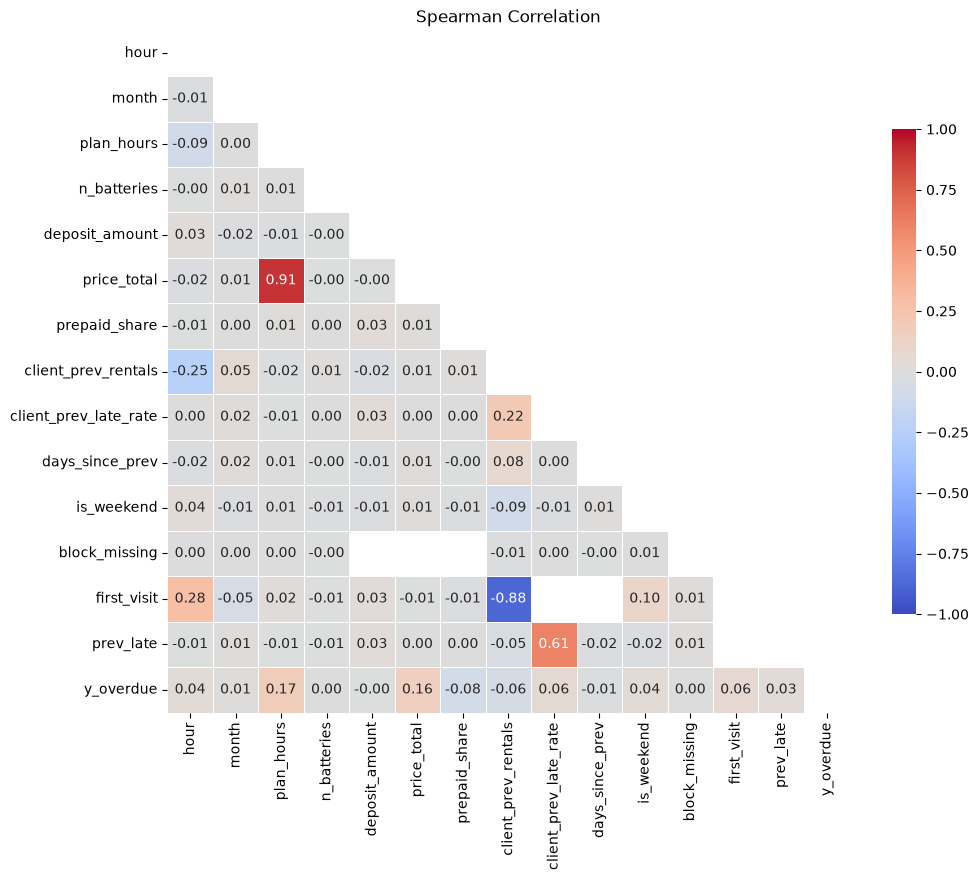

In [44]:
corr_cols = [c for c in NUM + BOOL if df[c].nunique() > 1]   # client_prev_lost constant is eliminated
corr = df[corr_cols + [TARGET]].astype("float64").corr(method="spearman")

mask = np.triu(np.ones_like(corr, dtype=bool))               # show only the lower triangle
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=.5,
            cbar_kws={"shrink": .7})
plt.title("Spearman Correlation")
plt.show()

In [45]:
pairs = corr.where(~mask).stack().rename_axis(["f1", "f2"]).reset_index(name="corr")
pairs = pairs.loc[pairs["corr"].abs() > 0.5].sort_values("corr", key=abs, ascending=False)
pairs.round(2)

,f1,f2,corr
77,price_total,plan_hours,0.91
187,first_visit,client_prev_rentals,-0.88
203,prev_late,client_prev_late_rate,0.61


In [46]:
# first visit = no prev rents?
print((df["first_visit"].astype(bool) == (df["client_prev_rentals"] == 0)).mean())

1.0


In [ ]:
d = df.dropna(subset=["price_total"]).copy()
d["price_ratio"] = d["price_total"] / d.groupby(d["plan_hours"].round(0))["price_total"].transform("median")
print(d.groupby(TARGET)["price_ratio"].describe().round(2))

# what explains the variation within the tariff
x = d[d["plan_hours"].round(0) == 24]
print(x.groupby("n_batteries")["price_total"].median())
print(x.groupby("model")["price_total"].median())

             count  mean   std   min   25%  50%   75%   max
y_overdue                                                  
0          19537.0  1.09  0.44  0.29  0.88  1.0  1.22  7.82
1           1740.0  1.07  0.34  0.67  0.88  1.0  1.21  5.95
n_batteries
1    1770.0
2    1800.0
Name: price_total, dtype: float64
model
Cargo 500    2250.0
Trail 350    1750.0
Urban 250    1490.0
Name: price_total, dtype: float64


There is no leak

## 6.2 CAT

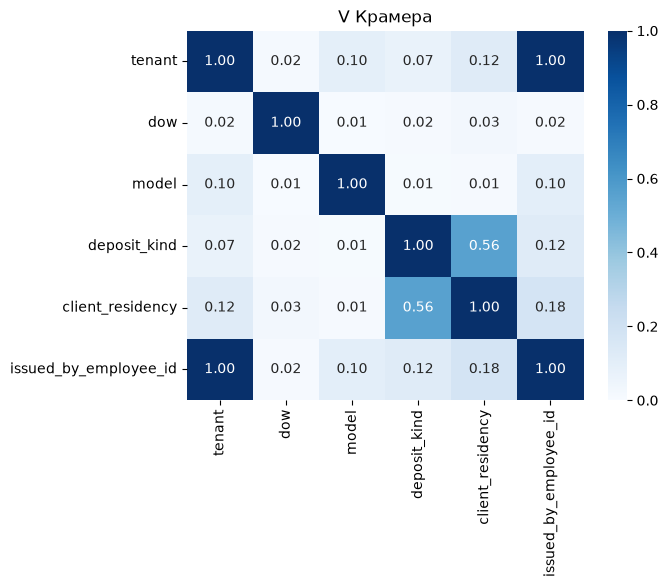

In [ ]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    return (chi2 / (n * (min(t.shape) - 1))) ** 0.5

cat_cols = [c for c in CAT if df[c].nunique() <= 20]          # with out issued_by_employee_id
cv = pd.DataFrame(
    [[cramers_v(df[a].fillna("NA"), df[b].fillna("NA")) for b in cat_cols] for a in cat_cols],
    index=cat_cols, columns=cat_cols)

sns.heatmap(cv, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramér's V")
plt.show()

## Conclusion
1. It is required to leave one attribute `first_visit` or `client_prev_rentals`